### Q1. Design a Cognitive Assistant for Reading Labels of medicine bottle (You can download Dataset from Internet)

Upload a medicine bottle image


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


Saving test1.jpg to test1 (2).jpg


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Medicine label text:
Pharmacy
At Na: 860015-5578
JOHN
GENERIC MEDICATIONE
TIme DAILY FORT
Utf: 180 TABS
Smith, Joe
No Relil?:
ORUG EXP: 2/16
TREE
Verify the extracted information with the original label before using the medicine.


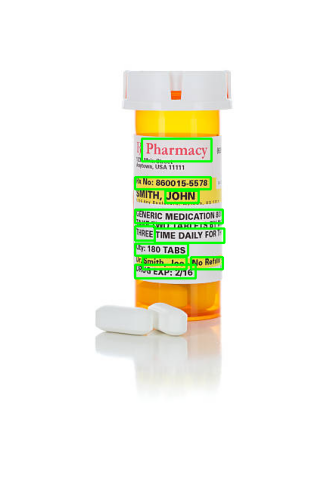

In [1]:
%pip -q install easyocr
import easyocr
import cv2
import matplotlib.pyplot as plt
from google.colab import files

reader = easyocr.Reader(['en'], gpu=False)
print('Upload a medicine bottle image')
uploaded = files.upload()
if uploaded:
    image = cv2.imread(next(iter(uploaded)))
    if image is None:
        print('Please upload a valid image.')
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        results = reader.readtext(gray)
        print('Medicine label text:')
        if not results:
            print('No readable text found. Try a clearer image.')
        for box, text, confidence in results:
            if confidence < 0.3:
                continue
            print(text)
            x1, y1 = map(int, box[0])
            x2, y2 = map(int, box[2])
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        print('Verify the extracted information with the original label before using the medicine.')
        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()

### 2. Design an Emotion-aware Cognitive Assistant using Facial Expression Detection

Upload a facial expression image


Saving test_for_emotion1.jpeg to test_for_emotion1 (4).jpeg
26-11-24 13:19:23 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100%|██████████| 119M/119M [00:01<00:00, 82.5MB/s]


26-11-24 13:19:38 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 53.6MB/s]


Predicted expression: fear
Confidence: 57.28 %
Assistant: Would you like some support?
Facial expressions may not reflect actual feelings.


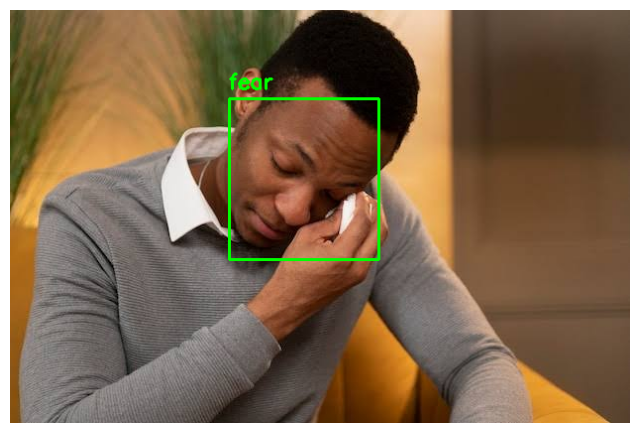

In [4]:
import cv2
import matplotlib.pyplot as plt
from deepface import DeepFace
from google.colab import files

responses = {
    'happy': 'Keep smiling and enjoy your day!',
    'sad': 'Would you like to talk or take a short break?',
    'angry': 'Try relaxing for a few minutes.',
    'fear': 'Would you like some support?',
    'surprise': 'Is there something you would like to share?',
    'disgust': 'Is something bothering you?',
    'neutral': 'How can I help you today?'
}

print('Upload a facial expression image')
uploaded = files.upload()

image = cv2.imread(next(iter(uploaded)))

try:
    results = DeepFace.analyze(
        img_path=image,
        actions=['emotion'],
        detector_backend='retinaface',
        enforce_detection=True
    )

    for result in results:
        emotion = result['dominant_emotion']
        confidence = result['emotion'][emotion]
        region = result['region']

        x,y = region['x'],region['y']
        w,h = region['w'],region['h']

        cv2.rectangle(image,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(image,emotion,(x,max(y-10,15)),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)

        print('Predicted expression:',emotion)
        print('Confidence:',round(confidence,2),'%')
        print('Assistant:',responses[emotion])

    print('Facial expressions may not reflect actual feelings.')

except Exception as e:
    print('Unable to detect face:',e)

plt.figure(figsize=(8,6))
plt.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()